# Portefeuille actions simulé (2 M€), version Python

**Projet académique ESME, parcours finance (3e année), octobre à décembre 2025.**

Ce notebook reprend le classeur Excel du projet (semaines 1 à 7) et :

1. **reproduit** la méthode de calcul du classeur pour vérifier les données ;
2. **corrige** deux limites du modèle Excel (taux de change de fin de semaine, prix d'exécution des ordres) ;
3. calcule les **indicateurs de performance et de risque**, comparés aux indices ;
4. teste la **sensibilité** des seuils stop-loss / take-profit.

| Fichier | Contenu |
|---|---|
| `data/semaines.csv` | dates, taux EUR/USD, seuils SL/TP, jours de rémunération du cash, capitaux du classeur |
| `data/positions.csv` | positions de chaque semaine : cours de début et de fin, nombre d'actions, ordres exécutés |
| `data/indices.csv` | Indice ESME, CAC 40 et S&P 500 aux dates de suivi |

La semaine 8 est exclue : ses données ne sont pas fiables.

> **Sur Google Colab** : ouvre le panneau *Fichiers*, crée un dossier `data` et glisses-y les trois fichiers CSV.

## 1. Paramètres et données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("data")
CAPITAL_INITIAL = 2_000_000   # capital de départ (EUR)
TAUX_CASH = 0.03              # rémunération du cash non investi
BASE_JOURS = 360              # convention de calcul des intérêts

semaines = pd.read_csv(DATA / "semaines.csv")
positions = pd.read_csv(DATA / "positions.csv")
indices = pd.read_csv(DATA / "indices.csv", parse_dates=["date"])

# Style des graphiques
COULEURS = {"excel": "#8D99AE", "corrigee": "#1F3A5F", "partout": "#2A9D8F",
            "sans": "#E9C46A", "esme": "#E76F51", "cac40": "#B56576", "sp500": "#6D597A"}
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11, "axes.titleweight": "bold"})

pct = lambda x: f"{x:+.2%}"
eur = lambda x: f"{x:,.0f} €".replace(",", " ")

print(f"{len(semaines)} semaines, {len(positions)} lignes de positions, {positions.societe.nunique()} sociétés")
semaines

7 semaines, 78 lignes de positions, 25 sociétés


,semaine,date_debut,date_fin,fx_debut,fx_fin,fx_fin_excel,seuil_sl,seuil_tp,jours_cash,capital_debut_excel,capital_fin_excel
0,1,2025-10-01,2025-10-09,1.1731,1.1614,1.1614,NaN,NaN,8,2000000.00,2003792.52
1,2,2025-10-09,2025-10-16,1.1614,1.1648,1.1614,NaN,NaN,7,2003793.00,2008507.22
2,3,2025-10-16,2025-11-05,1.1648,1.1494,1.1494,NaN,NaN,21,2008507.00,2046644.22
3,4,2025-11-05,2025-11-12,1.1494,1.1592,1.1592,0.95,1.10,7,2046644.00,2046602.79
4,5,2025-11-12,2025-11-19,1.1592,1.1538,1.1538,0.95,1.10,7,2046602.79,2000644.49
5,6,2025-11-19,2025-12-04,1.1538,1.1660,1.1660,0.98,1.04,14,2000644.49,2038607.49
6,7,2025-12-04,2025-12-11,1.1660,1.1703,1.1660,0.98,1.04,14,2038604.43,2041436.96


In [2]:
# Aperçu : nombre de lignes et devises par semaine
positions.groupby("semaine").agg(lignes=("societe", "count"),
                                 lignes_usd=("devise", lambda d: (d == "USD").sum()),
                                 ordres_excel=("etat_excel", lambda e: e.str.startswith("Vendre").sum()))

,lignes,lignes_usd,ordres_excel
semaine,,,
1,12,4,0
2,10,4,0
3,12,3,0
4,10,3,1
5,11,3,0
6,11,3,5
7,12,4,0


## 2. Moteur de calcul

Pour chaque semaine :

- les cours en dollars sont convertis en euros (taux de début pour l'achat, taux de fin pour la valorisation) ;
- le **cash non investi** = capital de début − valeur investie, rémunéré à 3 % (base 360) ;
- une ligne surveillée déclenche un **take-profit** si le cours de fin dépasse `seuil_tp × cours de début`, et un **stop-loss** s'il passe sous `seuil_sl × cours de début` (comme dans le classeur, avec des cours hebdomadaires) ;
- l'ordre est exécuté **au prix du seuil** ; le produit de la vente est rémunéré entre la date d'exécution et la fin de la semaine.

| Méthode | Taux de fin pour les titres US | Ligne vendue par un ordre |
|---|---|---|
| `excel` (reproduction) | taux utilisé dans le classeur | valorisée au cours de fin, comme si elle n'avait pas été vendue |
| `corrigee` | vrai taux de fin de semaine | valorisée au **prix d'exécution** de l'ordre |

In [3]:
def calculer_semaine(capital_debut, sem, pos, methode="corrigee", regle_partout=False,
                     seuil_sl=None, seuil_tp=None, execution_reelle=True, sans_regle=False):
    """Calcule le capital de fin d'une semaine. Renvoie (capital_fin, détail par ligne, cash initial)."""
    sl = sem.seuil_sl if seuil_sl is None else seuil_sl
    tp = sem.seuil_tp if seuil_tp is None else seuil_tp
    fx_fin = sem.fx_fin_excel if methode == "excel" else sem.fx_fin

    p = pos.copy()
    usd = p.devise.eq("USD")
    p["cours_eur_debut"] = np.where(usd, p.cours_debut / sem.fx_debut, p.cours_debut)
    p["cours_eur_fin"] = np.where(usd, p.cours_fin / fx_fin, p.cours_fin)
    p["valeur_debut"] = p.nb_actions * p.cours_eur_debut
    p["valeur_fin"] = p.nb_actions * p.cours_eur_fin

    # Lignes surveillées par la règle SL/TP
    if sans_regle or pd.isna(sl) or pd.isna(tp):
        surveillee = pd.Series(False, index=p.index)
    else:
        surveillee = p.regle_sl_tp.astype(bool) | regle_partout
    p["etat"] = "Actif"
    p.loc[surveillee & (p.cours_fin > tp * p.cours_debut), "etat"] = "Vendre (TP)"
    p.loc[surveillee & (p.cours_fin < sl * p.cours_debut), "etat"] = "Vendre (SL)"
    vendue = p.etat.ne("Actif")

    # Exécution au prix du seuil
    prix_exec = np.where(p.etat == "Vendre (TP)", tp * p.cours_debut, sl * p.cours_debut)
    if execution_reelle:   # taux de change et dates d'exécution notés dans le classeur, quand ils existent
        fx_exec = np.where(p.fx_execution.notna(), p.fx_execution, np.where(usd, sem.fx_fin, 1.0))
        jours = p.jours_interets_vente.fillna(0)
    else:                  # cas hypothétique : exécution convertie au taux de fin, sans intérêts
        fx_exec, jours = np.where(usd, sem.fx_fin, 1.0), 0
    p["produit_vente"] = np.where(vendue, prix_exec * p.nb_actions / fx_exec, 0.0)
    p["interets_vente"] = p.produit_vente * TAUX_CASH * jours / BASE_JOURS

    cash = capital_debut - p.valeur_debut.sum()
    interets_cash = cash * TAUX_CASH * sem.jours_cash / BASE_JOURS
    if methode == "excel":
        titres = p.valeur_fin.sum()
    else:
        titres = p.loc[~vendue, "valeur_fin"].sum() + p.loc[vendue, "produit_vente"].sum()
    capital_fin = titres + cash + interets_cash + p.interets_vente.sum()
    return capital_fin, p, cash


def simuler(methode="corrigee", **options):
    """Enchaîne les 7 semaines à partir du capital initial."""
    capital, lignes, details = CAPITAL_INITIAL, [], {}
    for sem in semaines.itertuples():
        capital_fin, detail, cash = calculer_semaine(capital, sem, positions[positions.semaine == sem.semaine],
                                                     methode, **options)
        lignes.append({"semaine": sem.semaine, "date_fin": sem.date_fin, "capital_debut": capital,
                       "investi": detail.valeur_debut.sum(), "exposition": detail.valeur_debut.sum() / capital,
                       "ordres": int(detail.etat.ne("Actif").sum()), "capital_fin": capital_fin,
                       "rendement": capital_fin / capital - 1})
        details[sem.semaine] = detail
        capital = capital_fin
    return pd.DataFrame(lignes).set_index("semaine"), details

## 3. Vérification : reproduction du classeur

On recalcule chaque semaine à partir du capital de début inscrit dans le classeur, avec la méthode `excel`, et on compare au capital de fin du classeur.

In [4]:
verif = []
for sem in semaines.itertuples():
    cap, _, _ = calculer_semaine(sem.capital_debut_excel, sem, positions[positions.semaine == sem.semaine], "excel")
    verif.append({"semaine": sem.semaine, "classeur": sem.capital_fin_excel, "python": cap,
                  "écart (€)": cap - sem.capital_fin_excel})
verif = pd.DataFrame(verif).set_index("semaine")
assert verif["écart (€)"].abs().max() < 20, "La reproduction s'écarte du classeur"
verif.style.format({"classeur": "{:,.2f}", "python": "{:,.2f}", "écart (€)": "{:+.2f}"})

,classeur,python,écart (€)
semaine,,,
1,"2,003,792.52","2,003,792.52",-0.00
2,"2,008,507.22","2,008,507.22",-0.00
3,"2,046,644.22","2,046,631.54",-12.68
4,"2,046,602.79","2,046,597.61",-5.18
5,"2,000,644.49","2,000,636.71",-7.78
6,"2,038,607.49","2,038,607.49",-0.00
7,"2,041,436.96","2,041,436.96",+0.00


**Lecture.** Le moteur retrouve le classeur à quelques euros près. Les écarts des semaines 3 à 5 viennent des cours en euros arrondis et saisis à la main dans le classeur.

La vérification a fait ressortir **deux limites du classeur** :

1. **Taux de change (semaines 2 et 7)** : les cours US de fin de semaine sont convertis au taux de *début* de semaine (formule `=F/H50` au lieu de `=F/I50`). La colonne `fx_fin_excel` reproduit cette erreur ; la méthode corrigée utilise le vrai taux de fin.
2. **Ordres exécutés** : une ligne vendue par stop-loss ou take-profit reste valorisée au cours de fin de semaine dans le capital, alors que la vente a eu lieu au prix du seuil.

## 4. Méthode corrigée et scénarios

In [5]:
scenarios = {
    "excel":    ("Classeur Excel (reproduction)", dict(methode="excel")),
    "corrigee": ("Méthode corrigée", dict(methode="corrigee")),
    "partout":  ("Corrigée, règle SL/TP sur toutes les lignes (S4 à S7)", dict(methode="corrigee", regle_partout=True)),
    "sans":     ("Corrigée, sans aucun ordre SL/TP", dict(methode="corrigee", sans_regle=True)),
}
resultats = {k: simuler(**opts)[0] for k, (_, opts) in scenarios.items()}
_, details_corr = simuler("corrigee")

synthese = pd.DataFrame({
    "Scénario": [nom for nom, _ in scenarios.values()],
    "Capital final": [eur(resultats[k].capital_fin.iloc[-1]) for k in scenarios],
    "Rendement": [pct(resultats[k].capital_fin.iloc[-1] / CAPITAL_INITIAL - 1) for k in scenarios],
    "Ordres": [resultats[k].ordres.sum() for k in scenarios],
}).set_index("Scénario")
synthese

,Capital final,Rendement,Ordres
Scénario,,,
Classeur Excel (reproduction),2 041 414 €,+2.07%,6
Méthode corrigée,2 029 445 €,+1.47%,6
"Corrigée, règle SL/TP sur toutes les lignes (S4 à S7)",2 030 533 €,+1.53%,10
"Corrigée, sans aucun ordre SL/TP",2 037 678 €,+1.88%,0


In [6]:
# Détail des ordres exécutés (méthode corrigée) : prix d'exécution contre cours de fin
ordres = pd.concat([d.assign(semaine=s) for s, d in details_corr.items()])
ordres = ordres[ordres.etat.ne("Actif")]
pd.DataFrame({
    "semaine": ordres.semaine, "société": ordres.societe, "ordre": ordres.etat,
    "cours début": ordres.cours_debut, "cours fin": ordres.cours_fin,
    "produit de la vente": ordres.produit_vente.map(eur),
    "valeur au cours de fin": ordres.valeur_fin.map(eur),
    "effet sur le capital": (ordres.produit_vente - ordres.valeur_fin).map(lambda x: f"{x:+,.0f} €".replace(",", " ")),
}).set_index("semaine")

,société,ordre,cours début,cours fin,produit de la vente,valeur au cours de fin,effet sur le capital
semaine,,,,,,,
4,Tesla,Vendre (SL),460.55,430.15,113 652 €,111 322 €,+2 330 €
6,Tesla,Vendre (TP),407.56,446.95,220 542 €,229 991 €,-9 450 €
6,Wheaton Precious Metals,Vendre (TP),104.03,108.50,61 610 €,61 415 €,+195 €
6,Eiffage,Vendre (TP),113.15,119.75,63 545 €,64 665 €,-1 120 €
6,Rexel,Vendre (TP),30.91,32.49,154 303 €,155 952 €,-1 649 €
6,Alstom,Vendre (SL),22.61,21.49,33 237 €,32 235 €,+1 002 €


**Lecture.** Le stop-loss sur Tesla (S4) a limité la perte. En S6, le take-profit sur Tesla a coûté environ 9 k€ : le cours a continué de monter bien au-delà du seuil de +4 %. Un take-profit serré coupe aussi les gains.

## 5. Performance et risque

Les indices sont relevés au début de chaque semaine, plus un dernier point en fin de semaine 7 : leurs 8 points couvrent donc la même période que le portefeuille. Le S&P 500 est en dollars.

In [7]:
def serie_capital(res):
    return pd.Series([CAPITAL_INITIAL, *res.capital_fin.values], index=range(0, len(res) + 1))

def indicateurs(serie, reference=None):
    r = serie.pct_change().dropna()
    sortie = {"Rendement total": serie.iloc[-1] / serie.iloc[0] - 1,
              "Volatilité hebdo": r.std(),
              "Drawdown max": (serie / serie.cummax() - 1).min(),
              "Meilleure semaine": r.max(), "Pire semaine": r.min()}
    if reference is not None:
        sortie["Semaines > Indice ESME"] = f"{(r.values > reference.values).sum()} / {len(r)}"
    return sortie

idx = indices.reset_index(drop=True)
r_esme = idx.indice_esme.pct_change().dropna()

tableau = {nom: indicateurs(serie_capital(resultats[k]), r_esme) for k, (nom, _) in scenarios.items()}
for col, nom in [("indice_esme", "Indice ESME"), ("cac40", "CAC 40"), ("sp500", "S&P 500 (USD)")]:
    tableau[nom] = indicateurs(idx[col])
tableau = pd.DataFrame(tableau).T
for c in ["Rendement total", "Drawdown max", "Meilleure semaine", "Pire semaine"]:
    tableau[c] = tableau[c].map(pct)
tableau["Volatilité hebdo"] = tableau["Volatilité hebdo"].map(lambda x: f"{x:.2%}")
tableau.fillna("")

,Rendement total,Volatilité hebdo,Drawdown max,Meilleure semaine,Pire semaine,Semaines > Indice ESME
Classeur Excel (reproduction),+2.07%,1.40%,-2.25%,+1.90%,-2.25%,6 / 7
Méthode corrigée,+1.47%,1.30%,-2.24%,+1.90%,-2.24%,5 / 7
"Corrigée, règle SL/TP sur toutes les lignes (S4 à S7)",+1.53%,1.30%,-2.24%,+1.90%,-2.24%,5 / 7
"Corrigée, sans aucun ordre SL/TP",+1.88%,1.40%,-2.25%,+1.90%,-2.25%,6 / 7
Indice ESME,-0.35%,1.06%,-1.73%,+1.46%,-1.50%,
CAC 40,-0.37%,1.12%,-1.74%,+1.45%,-1.48%,
S&P 500 (USD),+2.66%,2.14%,-3.52%,+3.38%,-3.52%,


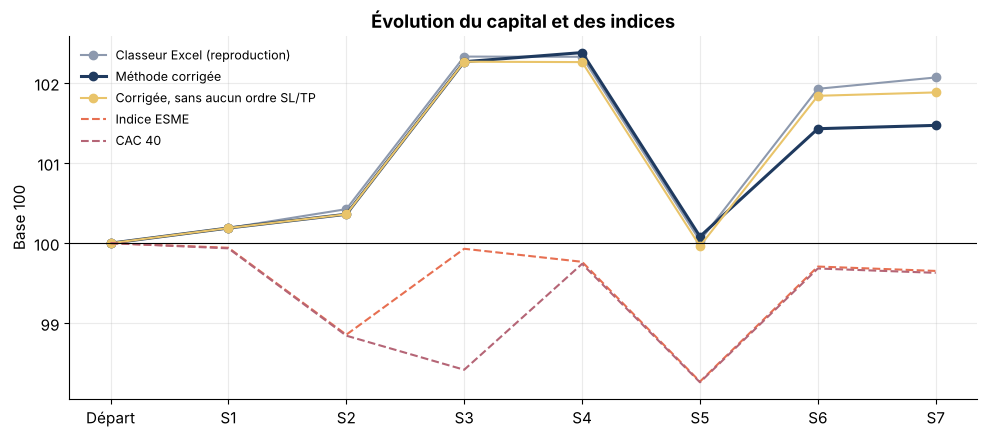

In [8]:
fig, ax = plt.subplots()
x = range(0, 8)
etiquettes = ["Départ"] + [f"S{s}" for s in semaines.semaine]
for k in ["excel", "corrigee", "sans"]:
    s = serie_capital(resultats[k])
    ax.plot(x, s / s.iloc[0] * 100, marker="o", lw=2.2 if k == "corrigee" else 1.5,
            color=COULEURS[k], label=scenarios[k][0])
for col, nom, couleur in [("indice_esme", "Indice ESME", "esme"), ("cac40", "CAC 40", "cac40")]:
    ax.plot(x, idx[col] / idx[col].iloc[0] * 100, ls="--", lw=1.5, color=COULEURS[couleur], label=nom)
ax.axhline(100, color="black", lw=0.8)
ax.set_xticks(list(x), etiquettes)
ax.set_ylabel("Base 100")
ax.set_title("Évolution du capital et des indices")
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

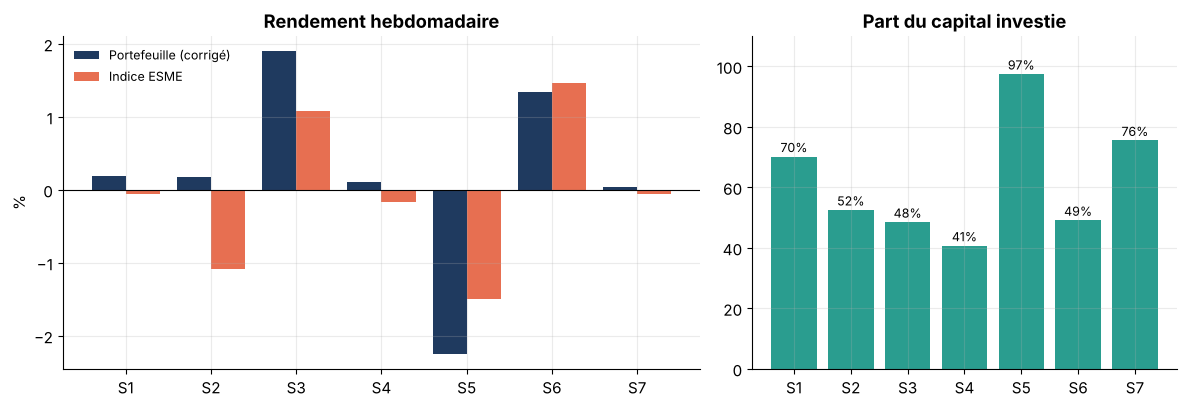

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [3, 2]})
res = resultats["corrigee"]
pos_x = np.arange(len(res))
ax1.bar(pos_x - 0.2, res.rendement * 100, width=0.4, color=COULEURS["corrigee"], label="Portefeuille (corrigé)")
ax1.bar(pos_x + 0.2, r_esme.values * 100, width=0.4, color=COULEURS["esme"], label="Indice ESME")
ax1.axhline(0, color="black", lw=0.8)
ax1.set_xticks(pos_x, [f"S{s}" for s in res.index]); ax1.set_ylabel("%")
ax1.set_title("Rendement hebdomadaire"); ax1.legend(frameon=False, fontsize=9)

ax2.bar(pos_x, res.exposition * 100, color=COULEURS["partout"])
for xi, v in zip(pos_x, res.exposition):
    ax2.text(xi, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=9)
ax2.set_xticks(pos_x, [f"S{s}" for s in res.index]); ax2.set_ylim(0, 110)
ax2.set_title("Part du capital investie")
plt.tight_layout(); plt.show()

## 6. Sensibilité des seuils stop-loss / take-profit

On rejoue les 7 semaines en appliquant la règle à **toutes les lignes et toutes les semaines**, pour différents seuils. Les positions restent celles réellement choisies chaque semaine, et les ordres sont convertis au taux de fin sans intérêts.

⚠️ C'est un exercice **hypothétique et dans l'échantillon** : avec 7 semaines, choisir *a posteriori* les « meilleurs » seuils reviendrait à du surapprentissage. Le but est de voir comment les seuils changent le résultat, pas de les optimiser.

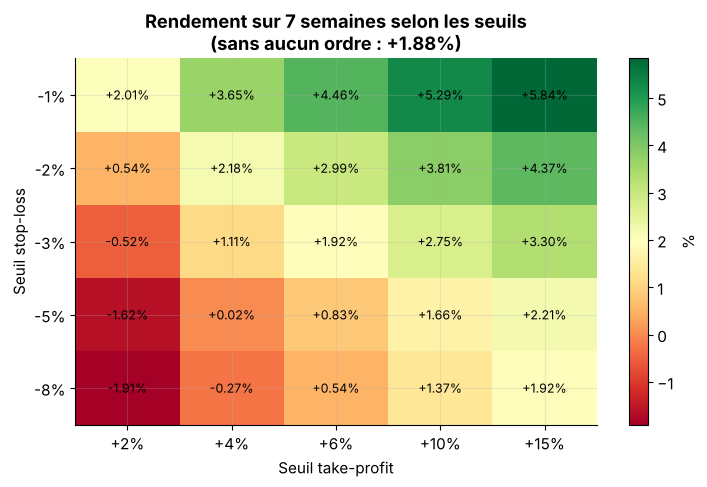

In [10]:
grille_sl = [0.99, 0.98, 0.97, 0.95, 0.92]
grille_tp = [1.02, 1.04, 1.06, 1.10, 1.15]
sensi = pd.DataFrame(index=[f"-{1 - s:.0%}" for s in grille_sl], columns=[f"+{t - 1:.0%}" for t in grille_tp], dtype=float)
for s in grille_sl:
    for t in grille_tp:
        res, _ = simuler("corrigee", regle_partout=True, seuil_sl=s, seuil_tp=t, execution_reelle=False)
        sensi.loc[f"-{1 - s:.0%}", f"+{t - 1:.0%}"] = res.capital_fin.iloc[-1] / CAPITAL_INITIAL - 1
reference = resultats["sans"].capital_fin.iloc[-1] / CAPITAL_INITIAL - 1

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(sensi.values * 100, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(grille_tp)), sensi.columns); ax.set_yticks(range(len(grille_sl)), sensi.index)
ax.set_xlabel("Seuil take-profit"); ax.set_ylabel("Seuil stop-loss")
for i in range(len(grille_sl)):
    for j in range(len(grille_tp)):
        ax.text(j, i, f"{sensi.values[i, j]:+.2%}", ha="center", va="center", fontsize=9)
ax.set_title(f"Rendement sur 7 semaines selon les seuils\n(sans aucun ordre : {reference:+.2%})")
fig.colorbar(im, ax=ax, label="%")
plt.tight_layout(); plt.show()

**Lecture : la grille montre surtout un biais du modèle.** Avec des cours hebdomadaires, la règle ne regarde que le cours de *fin* de semaine :

- un **stop-loss** n'est déclenché que si le titre finit la semaine sous le seuil. Dans la réalité, il serait aussi déclenché par une baisse passagère suivie d'une remontée (le titre est vendu bas, puis remonte sans nous). Le modèle ignore ces cas défavorables, donc **un stop-loss serré paraît bien meilleur qu'il ne l'est** ;
- un **take-profit** n'est déclenché que si le titre finit au-dessus du seuil. Dans la réalité, une hausse passagère suffirait. Le modèle ignore ces cas favorables, donc **un take-profit serré paraît moins bon qu'il ne l'est**.

C'est pour cela que le coin « stop-loss −1 %, take-profit +15 % » semble excellent. Pour tester sérieusement des seuils, il faut des **cours journaliers (plus hauts et plus bas)** et des données hors échantillon. Le même biais touche la règle du classeur Excel.

## 7. Limites et pistes

- **Données hebdomadaires** : la règle ne voit que le cours de fin de semaine (voir section 6) et suppose que l'ordre s'exécute exactement au seuil. Avec des cours journaliers, on retrouverait la vraie date de franchissement et le prix réel (y compris les gaps d'ouverture).
- **7 semaines** : aucun résultat n'est statistiquement significatif ; c'est la méthode qui compte.
- **Hypothèses simplificatrices** : portefeuille simulé, sans frais de transaction ni dividendes.
- **Pistes** : VaR historique, ratio de Sharpe, frais de courtage, backtest sur données journalières.

La cellule ci-dessous (facultative) télécharge les cours journaliers avec `yfinance` pour aller plus loin. Les tickers sont à vérifier, en particulier Sartorius (`DIM.PA` pour Sartorius Stedim Biotech, `SRT3.DE` pour Sartorius AG).

In [11]:
# Facultatif : cours journaliers (nécessite Internet et `pip install yfinance`)
TELECHARGER = False
if TELECHARGER:
    import yfinance as yf
    tickers = sorted(positions.ticker.unique())
    journalier = yf.download(tickers, start="2025-09-25", end="2025-12-15", auto_adjust=False)["Close"]
    display(journalier.tail())